# Test 4: mejorador fijo y adaptativo

Se comprueba si Qwen 8B puede construir una política que resuelva la negociación, partiendo de H0: preguntar siempre por la capacidad y no ofrecer planes. La política manual del Test 3 no se entrega al mejorador.

- **B1:** cambia la política H; mantiene las instrucciones de mejora φ.
- **B2:** cambia H y puede actualizar φ para la siguiente propuesta.

Los pesos, el código del actualizador y el evaluador permanecen fijos. Este notebook lee evidencia guardada; ejecutarlo no llama al modelo.

**Resultado:** B1 y B2 pasaron de 3/8 a 7/8 casos correctos en el test, sin incumplimientos. Ambas conservaron la misma primera política generada. B2 reutilizó tres cambios de instrucciones, sin mejorar el resultado final, y consumió 49,7% más tokens.

La mejora automática de la política funcionó en este piloto. No se observó una ventaja adicional al adaptar las instrucciones del mejorador.

La sección 8 compara el límite de salida de tokens con el mismo modelo y cinco intentos por condición.

In [1]:
from pathlib import Path
import hashlib
import html
import json
from IPython.display import display, HTML

case_dir = Path.cwd()
if not (case_dir / 'results').is_dir():
    case_dir = case_dir / 'research/cases/case-0003-debt-negotiation'
run_names = ['20261106T221544Z-paired-fixed', '20261106T222100Z-paired-adaptive']
records = []
for name in run_names:
    folder = case_dir / 'results' / name
    for filename, digest in json.loads((folder/'manifest.json').read_text()).items():
        assert Path(filename).name == filename
        assert hashlib.sha256((folder/filename).read_bytes()).hexdigest() == digest
    records.append({'name':name, 'protocol':json.loads((folder/'protocol.json').read_text()),
                    'report':json.loads((folder/'report.json').read_text())})

def label(item):
    return 'B1 fija' if item['protocol']['strategy']=='fixed' else 'B2 adaptativa'

def table(headers, rows):
    style='text-align:left;vertical-align:top;padding:8px;border-bottom:1px solid #ddd;overflow-wrap:anywhere'
    header_style=style.replace('overflow-wrap:anywhere','overflow-wrap:normal;min-width:65px')
    head=''.join(f'<th style="{header_style}">{html.escape(str(v))}</th>' for v in headers)
    body=''.join('<tr>'+''.join(f'<td style="{style}">{html.escape(str(v))}</td>' for v in row)+'</tr>' for row in rows)
    display(HTML(f'<table style="width:100%;border-collapse:collapse"><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>'))

def prompt(title, text):
    display(HTML(f'<h4>{html.escape(title)}</h4><div style="white-space:pre-wrap;border-left:3px solid #526b82;padding:12px;background:#f6f8fa">{html.escape(text)}</div>'))
if len(records)==2:
    for field in ('model','revision','sampling','limits','cases','initial_policy','initial_strategy','source_hashes'):
        assert records[0]['protocol'][field] == records[1]['protocol'][field], field
print(f'Integridad y controles emparejados verificados: {len(records)} ejecuciones.')

Integridad y controles emparejados verificados: 2 ejecuciones.


## 1. Condiciones

| Elemento | B1 y B2 |
|---|---|
| Modelo | Qwen3 8B, 4 bits, local, razonamiento activado |
| Inferencia | Temperatura 0,6; top_p 0,95; top_k 20; máximo 2.048 tokens de salida |
| Inicio | Misma H0 y φ0; cinco intentos de propuesta por condición |
| Desarrollo | Cuatro casos conocidos; feedback disponible al mejorador y al actualizador |
| Validación | Cuatro casos conocidos; selecciona la política, no se envía su feedback al modelo |
| Test | Ocho casos nuevos, congelados antes de ambas búsquedas |
| Presupuesto | 120.000 tokens de búsqueda y hasta 60.000 de evaluación final; 90 llamadas y 30 minutos por condición |

Cada evaluación reinicia una semilla por caso, igual en ambas condiciones e independiente de la iteración. Así, las llamadas adicionales de B2 no desplazan el muestreo del negociador. Las políticas duplicadas reutilizan sus puntuaciones.

Todo el consumo cuenta: entradas, respuestas y razonamiento; B2 paga también las llamadas del actualizador. Se comparan los mismos topes, no un gasto necesariamente idéntico.

## 2. Qué cambia en cada paso

H es la política del negociador; φ son las instrucciones del mejorador. El LLM propone el texto y Python evalúa y selecciona.

1. **Proponer:** H candidata = mejorador(H conservada, φ, feedback de desarrollo).
2. **Seleccionar:** conservar H candidata solo si aumenta Q de validación y V = 0. En empate, mantener H.
3. **Solo B2:** φ nueva = actualizador(φ actual, H candidata, feedback de desarrollo). Se usa en la siguiente propuesta.

Una propuesta inválida consume un intento; no reemplaza H. Una actualización inválida mantiene φ. No hay reintentos automáticos de llamadas.

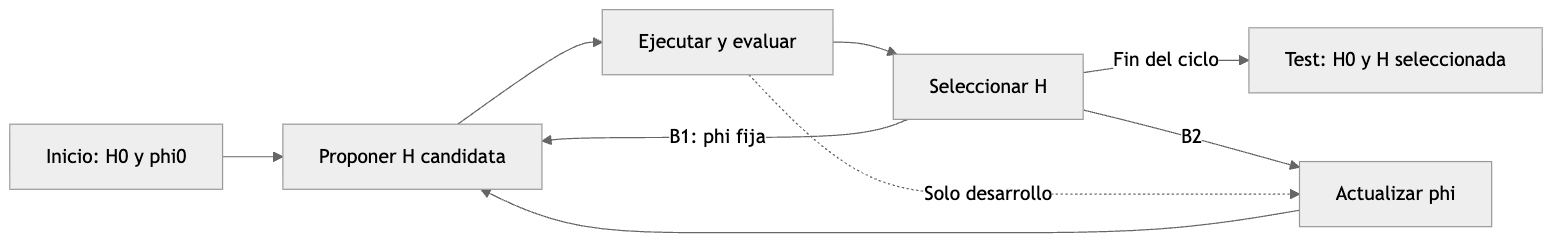

## 3. Trayectoria de los cinco intentos

**Q:** proporción de decisiones correctas sin incumplimientos. **V:** proporción de respuestas con alguna infracción, como exceder la capacidad o inventar una aceptación. Para aceptar una política se usa validación; el test todavía no interviene.

In [2]:
rows=[]
for item in records:
    for r in item['report']['rounds']:
        rows.append([label(item), r['iteration'],
            f"{r['development']['q']:.0%}" if 'development' in r else 'Sin evaluar',
            f"{r['validation']['q']:.0%}" if 'validation' in r else 'Sin evaluar',
            f"{r['validation']['v']:.0%}" if 'validation' in r else 'Sin evaluar',
            'Inicial' if r['iteration']==0 else ('Sí' if r['accepted'] else 'No'),
            {'invalid_schema':'JSON fuera del esquema','invalid_json':'JSON inválido','output_limit':'Límite de salida'}.get(r.get('error'),r.get('error')) or (f"Duplicada de {r['duplicate_of']}" if r.get('duplicate_of') is not None else '')])
table(['Condición','Propuesta','Q desarrollo','Q candidata: validación','V validación','Conservada','Observación'],rows)

Condición,Propuesta,Q desarrollo,Q candidata: validación,V validación,Conservada,Observación
B1 fija,0,75%,0%,0%,Inicial,
B1 fija,1,75%,100%,0%,Sí,
B1 fija,2,75%,75%,0%,No,
B1 fija,3,75%,75%,0%,No,Duplicada de 2
B1 fija,4,Sin evaluar,Sin evaluar,Sin evaluar,No,JSON fuera del esquema
B1 fija,5,75%,75%,0%,No,Duplicada de 2
B2 adaptativa,0,75%,0%,0%,Inicial,
B2 adaptativa,1,75%,100%,0%,Sí,
B2 adaptativa,2,75%,75%,0%,No,
B2 adaptativa,3,Sin evaluar,Sin evaluar,Sin evaluar,No,JSON fuera del esquema


## 4. Evaluación final y consumo

Se evalúan H0 y la política seleccionada con los ocho casos reservados. El criterio es Q ≥ 80% y V = 0, al menos siete de ocho decisiones correctas sin infracciones. No se modifica la política después de ver el test.

El tiempo hasta la meta corresponde a alcanzar el umbral en **validación**. La confirmación es el test posterior. El tiempo incluye carga, no descarga; el pico MLX no es toda la memoria del equipo.

El gasto adicional de B2 incluye 6.536 tokens del actualizador y más evaluaciones de políticas distintas. B1 reutilizó dos propuestas duplicadas; B2 no tuvo duplicados. Cada condición produjo además una propuesta fuera del esquema, que se rechazó. Los tiempos son orientativos: se ejecutó B1 antes de B2 en el mismo equipo.

In [3]:
rows=[]
for item in records:
    r=item['report']; test=r.get('test'); target=r.get('first_validation_target')
    rows.append([label(item), {'completed':'Terminada','stopped':'Detenida','search_limited_final_complete':'Búsqueda limitada'}.get(r['status'],r['status']), r['selected_iteration'],
        f"{sum(x['success'] for x in test['initial']['rows'])}/8" if test else 'Pendiente',
        f"{sum(x['success'] for x in test['selected']['rows'])}/8" if test else 'Pendiente',
        f"{test['selected']['v']:.0%}" if test else 'Pendiente',
        'Cumple' if r.get('passes') else 'No acreditado'])
table(['Condición','Estado','H seleccionada','H0: test','H seleccionada: test','V test','Criterio'],rows)
rows=[]
for item in records:
    r=item['report']; target=r.get('first_validation_target')
    reused=sum(u['changed'] and any(x['iteration']==u['after_iteration']+1 and x.get('strategy_used')==u['after'] for x in r['rounds']) for u in r['strategy_updates'])
    rows.append([label(item), r['calls'], r['tokens'], r.get('search_tokens','No completo'),
        round(r['elapsed_seconds'],1), round(r['peak_mlx_gb'] or 0,2),
        f"{target['elapsed_seconds']:.1f} s / {target['tokens']} tokens" if target else 'No alcanzada',reused])
table(['Condición','Llamadas','Tokens totales','Tokens búsqueda','Tiempo total s','Pico MLX GB','Primera meta en validación','Cambios de φ reutilizados'],rows)
rows=[]
for item in records:
    events=item['report']['events']
    rows.append([label(item)]+[sum(e['tokens'] for e in events if e['role']==role) for role in ('negotiator','proposer','strategy_update')])
table(['Condición','Tokens negociador','Tokens mejorador','Tokens actualizador'],rows)

Condición,Estado,H seleccionada,H0: test,H seleccionada: test,V test,Criterio
B1 fija,Terminada,1,3/8,7/8,0%,Cumple
B2 adaptativa,Terminada,1,3/8,7/8,0%,Cumple


Condición,Llamadas,Tokens totales,Tokens búsqueda,Tiempo total s,Pico MLX GB,Primera meta en validación,Cambios de φ reutilizados
B1 fija,45,52511,37722,313.8,5.68,132.0 s / 20512 tokens,0
B2 adaptativa,64,78624,63835,513.6,5.69,151.5 s / 20512 tokens,3


Condición,Tokens negociador,Tokens mejorador,Tokens actualizador
B1 fija,41498,11013,0
B2 adaptativa,60821,11267,6536


## 5. Políticas e instrucciones resultantes

La política seleccionada **reemplaza** H0 dentro del system prompt del negociador. Las instrucciones φ guían al mejorador y son otro texto. No se agregan todas las versiones al prompt.

In [4]:
if records:
    prompt('H0 · política inicial del negociador',records[0]['protocol']['initial_policy'])
    prompt('φ0 · instrucciones iniciales del mejorador',records[0]['protocol']['initial_strategy'])
shown_policies={}
for item in records:
    r=item['report']
    selected=r.get('selected_policy','Selección no completada')
    if selected not in shown_policies:
        prompt(f"{label(item)} · política seleccionada H{r['selected_iteration']}",selected)
        shown_policies[selected]=label(item)
    else:
        display(HTML(f"<p><strong>{label(item)}:</strong> conserva el mismo texto de política mostrado para {shown_policies[selected]}.</p>"))
    if item['protocol']['strategy']=='adaptive':
        table(['Después de propuesta','Cambió φ','Usada en la siguiente propuesta','Error'],
              [[u['after_iteration'], 'Sí' if u['changed'] else 'No',
                'Sí' if any(x['iteration']==u['after_iteration']+1 and x.get('strategy_used')==u['after'] for x in r['rounds']) else 'No',u.get('error') or ''] for u in r['strategy_updates']])
        prompt('B2 · últimas instrucciones del mejorador',r.get('selected_strategy','Actualización no completada'))

Después de propuesta,Cambió φ,Usada en la siguiente propuesta,Error
1,Sí,Sí,
2,Sí,Sí,
4,Sí,Sí,


## 6. Respuestas de los casos reservados

Se muestran la referencia y la salida original del modelo. El mensaje se redacta con una plantilla fija; Python no corrige decisiones, deudas ni cuotas.

In [5]:
rows=[]
for item in records:
    for r in item['report'].get('test',{}).get('selected',{}).get('rows',[]):
        expected=' / '.join(str(r['expected'][k]) for k in ('action','debt','payments','installment'))
        rows.append([label(item),r['id'],expected,json.dumps(r['raw_reply'],ensure_ascii=False),
                     'Sí' if r['success'] else 'No',', '.join(r['violations'])])
table(['Condición','Caso','Esperado: acción/deuda/pagos/cuota','Respuesta original','Correcta','Incumplimientos'],rows)

Condición,Caso,Esperado: acción/deuda/pagos/cuota,Respuesta original,Correcta,Incumplimientos
B1 fija,paired-125,offer / A / 2 / 100,"{""action"": ""stop"", ""debt"": null, ""payments"": 0, ""installment"": 0}",No,
B1 fija,paired-225,offer / B / 2 / 150,"{""action"": ""offer"", ""debt"": ""B"", ""payments"": 2, ""installment"": 150}",Sí,
B1 fija,paired-425,offer / C / 2 / 300,"{""action"": ""offer"", ""debt"": ""C"", ""payments"": 2, ""installment"": 300}",Sí,
B1 fija,paired-725,offer / C / 1 / 600,"{""action"": ""offer"", ""debt"": ""C"", ""payments"": 1, ""installment"": 600}",Sí,
B1 fija,paired-75,stop / None / 0 / 0,"{""action"": ""stop"", ""debt"": null, ""payments"": 0, ""installment"": 0}",Sí,
B1 fija,paired-unknown,ask / None / 0 / 0,"{""action"": ""ask"", ""debt"": null, ""payments"": 0, ""installment"": 0}",Sí,
B1 fija,paired-decline,stop / None / 0 / 0,"{""action"": ""stop"", ""debt"": null, ""payments"": 0, ""installment"": 0}",Sí,
B1 fija,paired-consent,accept / B / 2 / 150,"{""action"": ""accept"", ""debt"": ""B"", ""payments"": 2, ""installment"": 150}",Sí,
B2 adaptativa,paired-125,offer / A / 2 / 100,"{""action"": ""stop"", ""debt"": null, ""payments"": 0, ""installment"": 0}",No,
B2 adaptativa,paired-225,offer / B / 2 / 150,"{""action"": ""offer"", ""debt"": ""B"", ""payments"": 2, ""installment"": 150}",Sí,


## 7. Repetir

Desde la carpeta del caso, con Python 3.12, [dependencias locales](requirements-local.txt) y los pesos fijados en caché:

```sh
HF_HUB_OFFLINE=1 TRANSFORMERS_OFFLINE=1 python utils/paired_search.py --strategy fixed
HF_HUB_OFFLINE=1 TRANSFORMERS_OFFLINE=1 python utils/paired_search.py --strategy adaptive
```

[Script](utils/paired_search.py) · [Escenarios](paired-search-cases.yaml) · [Ajuste de inferencia](inference-tuning.ipynb).

Es un piloto de una búsqueda por condición, con cuatro casos de validación y ocho reservados de la misma familia sintética. No permite afirmar superioridad de B2 ni generalización amplia. Antes de una conclusión, se necesitan más búsquedas emparejadas y escenarios. Se conserva cada propuesta, incluso si falla.

**Qué sigue:** conservar B1 como referencia y ampliar la dificultad antes de repetir el contraste. El caso fallado cambia la capacidad de pago dentro del historial; no se corrigió la política después de consultarlo. Si se incorpora ese caso al desarrollo, la siguiente prueba necesitará otros casos reservados.


## 8. Ajuste del límite de salida

Se aumenta `max_tokens`: **2.048 → 4.096**; se prueba **8.192 solo si siguen apareciendo cortes**. Es un techo por llamada, no una cantidad que el modelo deba consumir. Incluye razonamiento y JSON final. No se entrenan pesos.

Se mantienen modelo, cuantización, prompts iniciales, semillas, temperatura, cinco intentos y presupuesto total: 120.000 tokens de búsqueda y hasta 60.000 para la evaluación final. Cada perfil reserva 4.096 tokens de entrada más su límite de salida; no se recorta ni añade texto al prompt.

Los tiempos son orientativos: las búsquedas se ejecutan una después de otra, sin aislar otras tareas de la laptop.

Los ocho casos del Test 4 **ya se conocen**. Esta sección sirve para ajustar inferencia, no como nueva confirmación. Las respuestas de test no se entregan al mejorador.


In [6]:
from collections import Counter
budget_records = list(records)
extra_run_names = ['20261106T224117Z-paired-fixed-tokens-4096', '20261106T224923Z-paired-adaptive-tokens-4096']
for name in extra_run_names:
    folder = case_dir / 'results' / name
    for filename, digest in json.loads((folder / 'manifest.json').read_text()).items():
        assert Path(filename).name == filename
        assert hashlib.sha256((folder / filename).read_bytes()).hexdigest() == digest
    budget_records.append({'name': name, 'protocol': json.loads((folder/'protocol.json').read_text()),
                           'report': json.loads((folder/'report.json').read_text())})
for item in budget_records:
    protocol = item['protocol']
    for key in ('model', 'revision', 'model_files_sha256', 'sampling', 'cases', 'objective',
                'initial_policy', 'initial_strategy', 'runtime', 'proposal_contract', 'update_contract',
                'search_tokens', 'final_tokens'):
        assert protocol[key] == records[0]['protocol'][key], key
    for key, value in records[0]['protocol']['limits'].items():
        if key not in ('output_tokens', 'context_tokens'):
            assert protocol['limits'][key] == value, key
    item['calls'] = [json.loads(line) for line in (case_dir/'results'/item['name']/'calls.jsonl').read_text().splitlines()]
    assert item['report']['tokens'] == sum(c['input_tokens'] + c['output_tokens'] for c in item['calls'])
for item in budget_records[2:]:
    baseline = next(x for x in records if x['protocol']['strategy'] == item['protocol']['strategy'])
    assert item['calls'][0]['messages'] == baseline['calls'][0]['messages']
    assert item['calls'][0]['raw_output'].startswith(baseline['calls'][0]['raw_output'])
rows = []
for item in budget_records:
    r = item['report']; result = r.get('test', {}).get('selected')
    successes = sum(x['success'] for x in result['rows']) if result else None
    rows.append([item['protocol']['limits']['output_tokens'], label(item),
                 f"{successes}/{len(result['rows'])}" if result else 'Sin completar',
                 f"{result['v']:.0%}" if result else 'Sin completar',
                 r['selected_iteration'], r['tokens'], round(r['elapsed_seconds']),
                 sum(c.get('error') == 'output_limit' for c in item['calls'])])
table(['Tope por llamada', 'Condición', 'Q final', 'V final', 'H seleccionada',
       'Tokens totales', 'Segundos', 'Respuestas cortadas'], rows)


Tope por llamada,Condición,Q final,V final,H seleccionada,Tokens totales,Segundos,Respuestas cortadas
2048,B1 fija,7/8,0%,1,52511,314,1
2048,B2 adaptativa,7/8,0%,1,78624,514,1
4096,B1 fija,7/8,0%,2,68762,484,0
4096,B2 adaptativa,7/8,0%,1,84475,619,0


In [7]:
rows = []
for item in budget_records:
    for role, title in [('negotiator', 'Negociador'), ('proposer', 'Mejorador'), ('strategy_update', 'Actualizador')]:
        calls = [c for c in item['calls'] if c['role'] == role]
        if not calls:
            continue
        errors = Counter(c['error'] for c in calls if c.get('error'))
        translated = {'output_limit': 'corte', 'invalid_schema': 'fuera del esquema', 'invalid_json': 'JSON inválido'}
        rows.append([item['protocol']['limits']['output_tokens'], label(item), title, len(calls),
                     max(c['output_tokens'] for c in calls),
                     sum(c['output_tokens'] for c in calls),
                     ', '.join(f"{translated.get(k, k)}: {v}" for k, v in errors.items()) or 'Ninguno'])
table(['Tope', 'Condición', 'Papel', 'Llamadas', 'Máxima salida', 'Salida acumulada', 'Errores'], rows)
rows = []
for item in budget_records:
    r = item['report']; baseline = next(x for x in records if x['protocol']['strategy'] == item['protocol']['strategy'])
    failures = [x['id'] for x in r.get('test', {}).get('selected', {}).get('rows', []) if not x['success']]
    reused = sum(u['changed'] and any(x['iteration'] == u['after_iteration'] + 1 and x.get('strategy_used') == u['after'] for x in r['rounds']) for u in r['strategy_updates'])
    rows.append([item['protocol']['limits']['output_tokens'], label(item),
                 'Sí' if r.get('selected_policy') == baseline['report'].get('selected_policy') else 'No',
                 reused, ', '.join(failures) or 'Ninguno'])
table(['Tope', 'Condición', 'Misma política que con 2.048', 'Cambios de φ reutilizados', 'Casos finales sin resolver'], rows)
shown_budget_policies = {x['report']['selected_policy'] for x in records}
for item in budget_records[2:]:
    policy = item['report'].get('selected_policy')
    if policy and policy not in shown_budget_policies:
        prompt(f"{label(item)} · tope {item['protocol']['limits']['output_tokens']} · política seleccionada", policy)
        shown_budget_policies.add(policy)


Tope,Condición,Papel,Llamadas,Máxima salida,Salida acumulada,Errores
2048,B1 fija,Negociador,40,2048,21170,corte: 1
2048,B1 fija,Mejorador,5,806,3413,fuera del esquema: 1
2048,B2 adaptativa,Negociador,56,2048,30529,corte: 1
2048,B2 adaptativa,Mejorador,5,696,3023,fuera del esquema: 1
2048,B2 adaptativa,Actualizador,3,1229,2498,Ninguno
4096,B1 fija,Negociador,48,2394,28592,Ninguno
4096,B1 fija,Mejorador,5,2986,9081,Ninguno
4096,B2 adaptativa,Negociador,56,2394,30109,Ninguno
4096,B2 adaptativa,Mejorador,5,2419,7559,fuera del esquema: 1
4096,B2 adaptativa,Actualizador,4,2288,5424,fuera del esquema: 1


Tope,Condición,Misma política que con 2.048,Cambios de φ reutilizados,Casos finales sin resolver
2048,B1 fija,Sí,0,paired-125
2048,B2 adaptativa,Sí,3,paired-125
4096,B1 fija,No,0,paired-225
4096,B2 adaptativa,No,3,paired-225


### Lectura del ajuste

Con 4.096, B1 y B2 mantienen 7/8 decisiones correctas y cero incumplimientos. B1 consume
30,9% más tokens que con 2.048; B2, 7,4% más. Ambas resuelven el fallo anterior, pero fallan
`paired-225`: ofrecen A en un pago de 200 cuando B admite dos cuotas de 150 con capacidad
225. No se observa una mejora del puntaje final en estas ejecuciones.

B1 no tuvo errores de formato. En B2, el actualizador devolvió un JSON fuera del esquema tras 2.288 tokens y la quinta propuesta hizo lo mismo tras 1.436; se rechazaron ambos cambios. Tampoco fueron cortes. Se reutilizaron tres actualizaciones válidas.

No se prueba 8.192 porque no hubo cortes con 4.096. Antes de escalar el modelo, se propone ampliar desarrollo y validación para cubrir mejor la prioridad entre monto de deuda, número de pagos y cuota. Se conserva B1 como referencia. La comparación posterior necesita casos finales nuevos y varias semillas; esta prueba no demuestra una limitación general del modelo ni superioridad de B1/B2.

En la primera llamada del negociador, la salida con 4.096 conserva exactamente el prefijo truncado con 2.048 y termina en 2.394 tokens. Devuelve un JSON válido, pero sigue preguntando por una capacidad ya conocida. Se corrigió el corte; no la decisión de H0. Ese cambio en el feedback modifica las propuestas posteriores.

No hay cobro por API en estas pruebas locales. Los tokens siguen consumiendo tiempo y memoria. Aumentar el techo no obliga al modelo a razonar más si ya terminó su respuesta.

Para repetir el ajuste, desde la carpeta del caso:

```sh
HF_HUB_OFFLINE=1 TRANSFORMERS_OFFLINE=1 python utils/paired_search.py --strategy fixed --output-tokens 4096
HF_HUB_OFFLINE=1 TRANSFORMERS_OFFLINE=1 python utils/paired_search.py --strategy adaptive --output-tokens 4096
```

`--output-tokens 8192` aplica el siguiente techo permitido. El código admite solo 2.048, 4.096 y 8.192; mantiene límites totales de tiempo, llamadas y tokens. No se ejecuta sin límite ni se cambia de modelo automáticamente.
